# 02 — Feature Engineering & Train/Test Split

Wafer maps come in 346 different shapes, but standard ML models need **the same columns for every row**.
This notebook turns each map into **69 size-independent features**, then creates a **lot-grouped, stratified
train/test split** and seals the test set.

The extraction logic lives in `src/features.py` (so modelling and any future deployment reuse exactly the same
code). The full run is done by `python src/build_features.py` (~4 min on 12 cores) and cached to
`data/features.parquet`; this notebook loads that file, or builds it if missing.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import ListedColormap

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from features import FEATURE_NAMES, extract_features

sns.set_theme(style="whitegrid")
FIG_DIR = ROOT / "reports" / "figures"
WAFER_CMAP = ListedColormap(["white", "#9ecae1", "#d62728"])
CLASS_ORDER = ["none", "Edge-Ring", "Edge-Loc", "Center", "Loc",
               "Scratch", "Random", "Donut", "Near-full"]

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## Feature groups

| Group | # | What it measures | Classes it helps separate |
|---|---|---|---|
| Global | 2 | `log_n_die` (wafer size), `density` (share of defective dies) | Near-full, Random vs rest |
| Rings | 4 | Defect density in 4 concentric rings, centre → edge | Center, Donut, Edge-Ring |
| Edge quadrants | 5 | Density in top/right/bottom/left of the edge zone + `edge_asymmetry` (max − min) | Edge-Ring (uniform) vs Edge-Loc (one-sided) |
| 3×3 grid | 9 | Density in a 3×3 grid over the wafer | Where a local blob sits (Loc, Center) |
| Radon | 40 | Mean and std of Radon-transform projections across 60 angles, resampled to 20 points | Lines (Scratch) vs symmetric patterns |
| Cluster geometry | 9 | Size, elongation, compactness and position of the largest connected defect cluster | Scratch (elongated), Center (central), Edge-Loc (at rim) |

**Design choices**
- Every feature is a **ratio or normalised position** (0 = centre, 1 = rim), so a 26×26 wafer and a 200×200
  wafer are directly comparable.
- Radon projections are divided by the projection of the wafer outline → *fraction* of defective dies along each
  line, not a raw count that would grow with wafer size.
- No cleaning of the maps was needed: values are always 0/1/2 and there are no missing values
  (checked in 01_eda). The 4 wafers with < 100 dies are kept — they are valid `none` wafers.

## Worked example — one `Center` wafer → one row of numbers

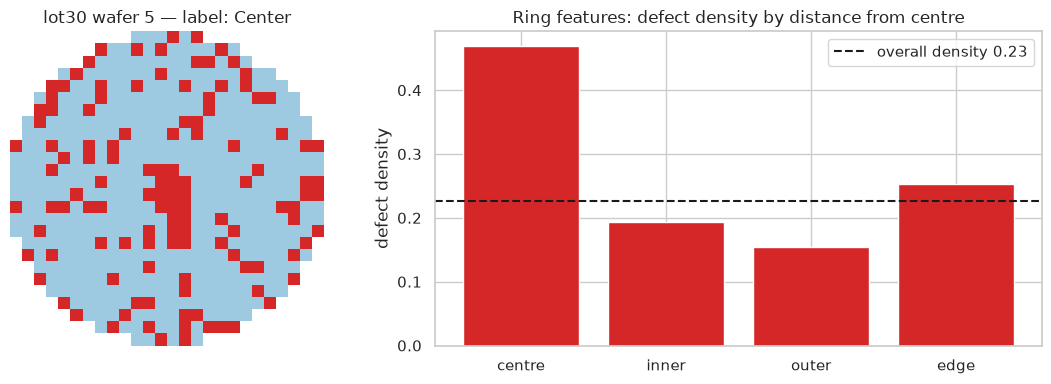

,log_n_die,density,ring_0,ring_1,ring_2,ring_3,edge_top,edge_right,edge_bottom,edge_left,...,grid_22,n_clusters_per_die,largest_area_frac,largest_share_of_defects,largest_perimeter_norm,largest_major_axis_norm,largest_eccentricity,largest_solidity,largest_extent,largest_dist_from_centre
value,6.279,0.227,0.469,0.193,0.154,0.253,0.281,0.25,0.262,0.219,...,0.239,0.077,0.036,0.157,0.687,0.314,0.907,0.826,0.679,0.096


In [2]:
labelled = pd.read_pickle(ROOT / "data" / "labelled.pkl")
example = labelled.loc[645]
f = pd.Series(extract_features(example["waferMap"]), index=FEATURE_NAMES)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.6]})
axes[0].imshow(example["waferMap"], cmap=WAFER_CMAP, vmin=0, vmax=2, interpolation="nearest")
axes[0].set(title=f"{example['lotName']} wafer {example['waferIndex']} — label: {example['failureType']}")
axes[0].axis("off")
rings = f[[f"ring_{i}" for i in range(4)]]
axes[1].bar(["centre", "inner", "outer", "edge"], rings.values, color="#d62728")
axes[1].axhline(f["density"], ls="--", c="k", label=f"overall density {f['density']:.2f}")
axes[1].set(title="Ring features: defect density by distance from centre", ylabel="defect density")
axes[1].legend()
plt.tight_layout(); savefig("feature_example"); plt.show()

f.drop([c for c in FEATURE_NAMES if c.startswith("radon")]).round(3).to_frame("value").T

## Build or load the full feature table

In [3]:
FEAT_PATH = ROOT / "data" / "features.parquet"
if not FEAT_PATH.exists():
    subprocess.run([sys.executable, str(ROOT / "src" / "build_features.py")], check=True)

feats = pd.read_parquet(FEAT_PATH)
del labelled  # free memory; the raw maps are no longer needed
print(feats.shape)
feats.head()

(172950, 74)


,lotName,waferIndex,dieSize,failureType,split,log_n_die,density,ring_0,ring_1,ring_2,...,radon_std_19,n_clusters_per_die,largest_area_frac,largest_share_of_defects,largest_perimeter_norm,largest_major_axis_norm,largest_eccentricity,largest_solidity,largest_extent,largest_dist_from_centre
0,lot1,1,1683.0,none,train,7.428333,0.052288,0.04,0.042763,0.041667,...,0.0,0.045752,0.001783,0.034091,0.024376,0.069489,1.000000,1.000000,1.00,0.901460
1,lot1,2,1683.0,none,train,7.428333,0.051099,0.04,0.032895,0.035714,...,0.0,0.038622,0.003565,0.069767,0.121879,0.092837,0.925274,0.857143,0.75,0.976610
2,lot1,3,1683.0,none,train,7.428333,0.039216,0.02,0.029605,0.005952,...,0.0,0.032086,0.002377,0.060606,0.053800,0.099579,0.974669,0.800000,0.50,0.989552
3,lot1,4,1683.0,none,train,7.428333,0.061794,0.06,0.036184,0.037698,...,0.0,0.047534,0.002971,0.048077,0.098369,0.122938,0.962552,0.625000,0.50,0.983963
4,lot1,5,1683.0,none,train,7.428333,0.042187,0.01,0.032895,0.033730,...,0.0,0.035056,0.001188,0.028169,0.000000,0.042553,1.000000,1.000000,1.00,0.981204


## Do the features capture the patterns we saw? — class profiles

Median value of key features per class. If the features work, each class should have its own fingerprint.

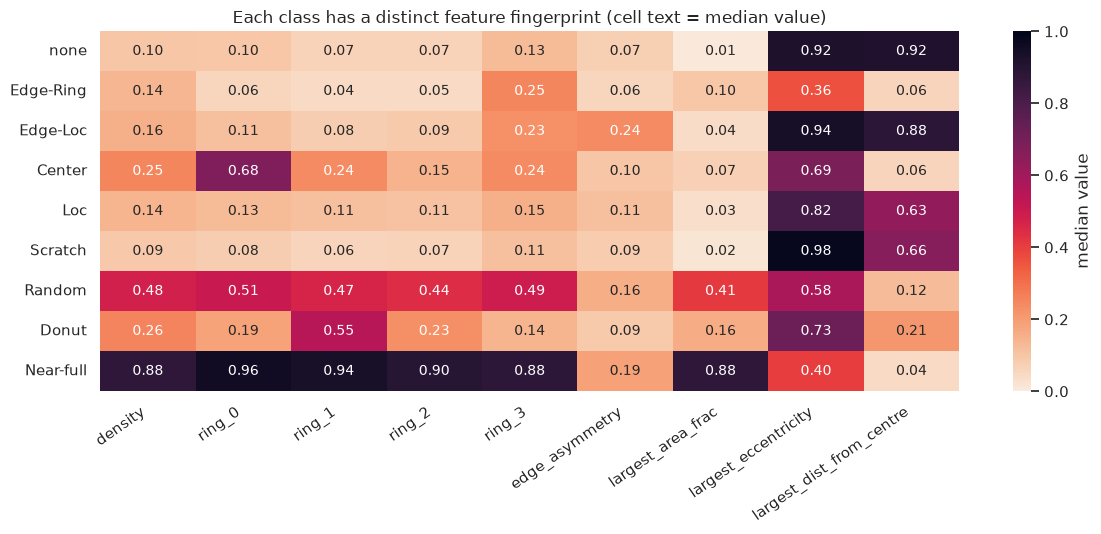

In [4]:
key = ["density", "ring_0", "ring_1", "ring_2", "ring_3", "edge_asymmetry",
       "largest_area_frac", "largest_eccentricity", "largest_dist_from_centre"]
profile = feats.groupby("failureType")[key].median().reindex(CLASS_ORDER).astype(float)
# All these features run from 0 to 1, so one shared scale keeps colours comparable across columns

fig, ax = plt.subplots(figsize=(12, 5.5))
sns.heatmap(profile, annot=True, fmt=".2f", cmap="rocket_r", vmin=0, vmax=1, annot_kws={"size": 10},
            cbar_kws={"label": "median value"}, ax=ax)
ax.set(title="Each class has a distinct feature fingerprint (cell text = median value)", xlabel="", ylabel="")
plt.xticks(rotation=35, ha="right")
plt.tight_layout(); savefig("class_feature_fingerprint"); plt.show()

**Reading the fingerprint**
- **Center**: centre ring (`ring_0`) much denser than the edge; largest cluster sits near the centre.
- **Edge-Ring**: outermost ring (`ring_3`) densest and uniform all round (asymmetry 0.06). Its largest cluster *is* the ring, so the cluster's centre point sits at the wafer centre (0.06) and it looks round (eccentricity 0.36).
- **Edge-Loc**: dense at the edge *on one side* → highest `edge_asymmetry` (0.24); cluster sits at the rim (0.88). Same ring_3 as Edge-Ring, but asymmetry and cluster position tell them apart.
- **Donut**: middle rings densest, centre lower.
- **Near-full**: everything ~0.9; the largest cluster covers most of the wafer.
- **none / Loc / Scratch** are the closest together → expect the most confusion between them.

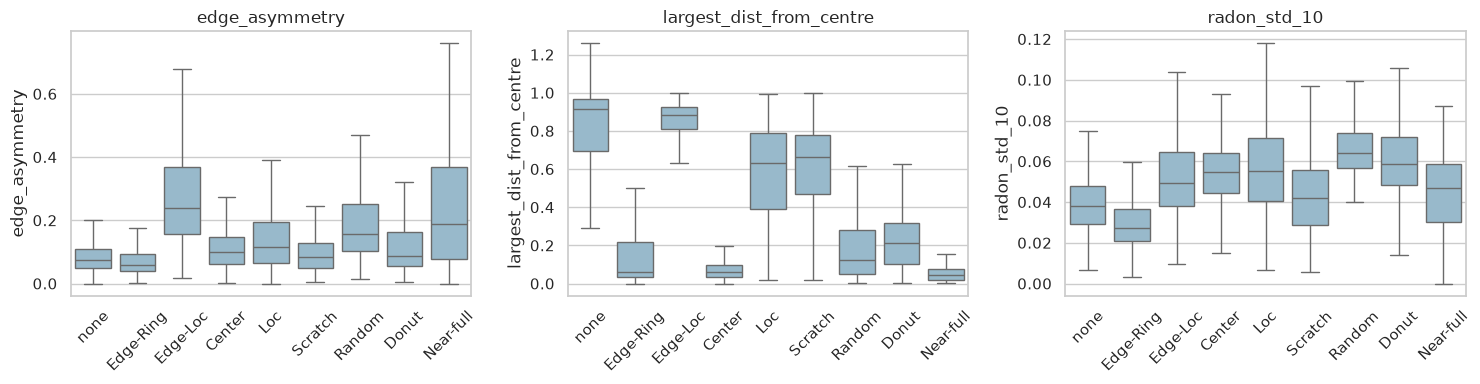

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["edge_asymmetry", "largest_dist_from_centre", "radon_std_10"]):
    sns.boxplot(data=feats, x="failureType", y=col, order=CLASS_ORDER, showfliers=False,
                color="#8fbcd4", ax=ax)
    ax.set(title=col, xlabel="")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); savefig("feature_boxplots"); plt.show()

## Train/test split — stratified *and* grouped by lot

- `StratifiedGroupKFold(n_splits=5)`; one fold (~20% of wafers) becomes the **test set**.
- **Grouped by `lotName`**: no lot appears in both train and test (EDA insight 4: ~90% of a lot's defects share
  one type, so mixing lots would leak near-duplicates into the test set).
- **Stratified by `failureType`**: each class has roughly the same share in train and test
  (unlike the dataset's own `trainTestLabel`, EDA insight 5).

In [6]:
train_lots = set(feats.loc[feats.split == "train", "lotName"])
test_lots = set(feats.loc[feats.split == "test", "lotName"])
print(f"train: {len(train_lots):,} lots | test: {len(test_lots):,} lots | overlap: {len(train_lots & test_lots)}")

split_table = pd.crosstab(feats["failureType"], feats["split"]).reindex(CLASS_ORDER)[["train", "test"]]
split_table["test_share_%"] = (100 * split_table["test"] / split_table.sum(axis=1)).round(1)
split_table.loc["TOTAL"] = split_table[["train", "test"]].sum().tolist() + [
    round(100 * split_table["test"].sum() / split_table[["train", "test"]].to_numpy().sum(), 1)]
split_table

train: 8,601 lots | test: 2,161 lots | overlap: 0


split,train,test,test_share_%
failureType,,,
none,117951,29480,20.0
Edge-Ring,7744,1936,20.0
Edge-Loc,4151,1038,20.0
Center,3435,859,20.0
Loc,2874,719,20.0
Scratch,954,239,20.0
Random,693,173,20.0
Donut,444,111,20.0
Near-full,119,30,20.1


## Leakage controls (for the slides)

1. **Lot-grouped split** — no lot in both train and test; cross-validation during tuning will also use
   `StratifiedGroupKFold` on the training lots only.
2. **Per-wafer features only** — each feature is computed from that wafer's own map, never from statistics of
   other wafers, so feature extraction cannot leak test information.
3. **Scaling inside a `Pipeline`** — the `StandardScaler` (needed for logistic regression) is fit on training
   folds only, never on the test set.
4. **Resampling on train only** — any downsampling of `none` or class weighting is applied to training data;
   the test set keeps the real-world class mix.
5. **Dropped columns** — `trainTestLabel` (unreliable split) and `waferIndex` (position in lot, not a physical
   property) are not used as features. `dieSize` equals the die count, already captured by `log_n_die`.

**The test set is now sealed** — it will be used once, in `04_evaluation.ipynb`.